In [1]:
import zipfile
import os

zip_path = "/content/DeepWeeds-master.zip"  # Change if your ZIP has another name
extract_path = "/content/DeepWeeds"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")
print(os.listdir(extract_path)[:20])

Dataset extracted!
['DeepWeeds-master']


In [2]:
import os

for root, dirs, files in os.walk("/content/DeepWeeds"):
    print(root, "->", len(files), "files")
    if root.count(os.sep) > 4:
        dirs[:] = []

/content/DeepWeeds -> 0 files
/content/DeepWeeds/DeepWeeds-master -> 5 files
/content/DeepWeeds/DeepWeeds-master/labels -> 16 files
/content/DeepWeeds/DeepWeeds-master/tensorrt -> 0 files
/content/DeepWeeds/DeepWeeds-master/tensorrt/src -> 2 files


In [3]:
import os

base = "/content/DeepWeeds/DeepWeeds-master"

for root, dirs, files in os.walk(base):
    for filename in files:
        path = os.path.join(root, filename)
        print(path, f"({os.path.getsize(path) / 1024:.1f} KB)")

/content/DeepWeeds/DeepWeeds-master/README.md (6.4 KB)
/content/DeepWeeds/DeepWeeds-master/LICENSE (11.1 KB)
/content/DeepWeeds/DeepWeeds-master/requirements.txt (0.1 KB)
/content/DeepWeeds/DeepWeeds-master/deepweeds.py (15.6 KB)
/content/DeepWeeds/DeepWeeds-master/.gitignore (0.0 KB)
/content/DeepWeeds/DeepWeeds-master/labels/val_subset2.csv (82.1 KB)
/content/DeepWeeds/DeepWeeds-master/labels/val_subset3.csv (82.1 KB)
/content/DeepWeeds/DeepWeeds-master/labels/train_subset3.csv (246.2 KB)
/content/DeepWeeds/DeepWeeds-master/labels/test_subset0.csv (82.2 KB)
/content/DeepWeeds/DeepWeeds-master/labels/val_subset0.csv (82.1 KB)
/content/DeepWeeds/DeepWeeds-master/labels/test_subset3.csv (82.0 KB)
/content/DeepWeeds/DeepWeeds-master/labels/test_subset2.csv (82.1 KB)
/content/DeepWeeds/DeepWeeds-master/labels/labels.csv (584.9 KB)
/content/DeepWeeds/DeepWeeds-master/labels/val_subset4.csv (82.1 KB)
/content/DeepWeeds/DeepWeeds-master/labels/test_subset1.csv (82.1 KB)
/content/DeepWeeds/De

In [4]:
import pandas as pd

csv_path = "/content/DeepWeeds/DeepWeeds-master/labels/labels.csv"

df = pd.read_csv(csv_path)

print("Dataset rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset rows and columns: (17509, 3)

Column names:
['Filename', 'Label', 'Species']

First five rows:


,Filename,Label,Species
0,20160928-140314-0.jpg,0,Chinee apple
1,20160928-140337-0.jpg,0,Chinee apple
2,20160928-140731-0.jpg,0,Chinee apple
3,20160928-140747-0.jpg,0,Chinee apple
4,20160928-141107-0.jpg,0,Chinee apple


In [5]:
!pip -q install gdown

In [6]:
import gdown
import os
import zipfile

zip_path = "/content/images.zip"

url = "https://drive.google.com/file/d/1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj/view"

gdown.download(url, zip_path, quiet=False, fuzzy=True)

print("ZIP downloaded:", os.path.exists(zip_path))
if os.path.exists(zip_path):
    print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

Downloading...
From (original): https://drive.google.com/uc?id=1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj
From (redirected): https://drive.google.com/uc?id=1xnK3B6K6KekDI55vwJ0vnc2IGoDga9cj&confirm=t&uuid=a0fdba71-19ea-4ef2-b7ab-7de6035688d6
To: /content/images.zip
100%|██████████| 492M/492M [00:06<00:00, 70.7MB/s]

ZIP downloaded: True
ZIP size (MB): 468.75


In [7]:
images_dir = "/content/DeepWeeds/DeepWeeds-master/images"

os.makedirs(images_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(images_dir)

print("Extraction complete!")

Extraction complete!


In [8]:
import glob
import pandas as pd
import os

csv_path = "/content/DeepWeeds/DeepWeeds-master/labels/labels.csv"
df = pd.read_csv(csv_path)

image_paths = glob.glob(
    "/content/DeepWeeds/DeepWeeds-master/images/**/*.jpg",
    recursive=True
)

print("CSV records:", len(df))
print("Images found:", len(image_paths))
print("Example image:", image_paths[0] if image_paths else "None found")

CSV records: 17509
Images found: 17509
Example image: /content/DeepWeeds/DeepWeeds-master/images/20180119-115245-1.jpg


In [9]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

CSV_PATH = "/content/DeepWeeds/DeepWeeds-master/labels/labels.csv"
IMAGE_DIR = "/content/DeepWeeds/DeepWeeds-master/images"

df = pd.read_csv(CSV_PATH)

# Create a full path for every image.
df["image_path"] = df["Filename"].apply(
    lambda name: os.path.join(IMAGE_DIR, name)
)

# Check that every CSV filename exists.
df["exists"] = df["image_path"].apply(os.path.isfile)

print("Total records:", len(df))
print("Images found:", df["exists"].sum())
print("Missing images:", (~df["exists"]).sum())

display(df.head())


Total records: 17509
Images found: 17509
Missing images: 0


,Filename,Label,Species,image_path,exists
0,20160928-140314-0.jpg,0,Chinee apple,/content/DeepWeeds/DeepWeeds-master/images/201...,True
1,20160928-140337-0.jpg,0,Chinee apple,/content/DeepWeeds/DeepWeeds-master/images/201...,True
2,20160928-140731-0.jpg,0,Chinee apple,/content/DeepWeeds/DeepWeeds-master/images/201...,True
3,20160928-140747-0.jpg,0,Chinee apple,/content/DeepWeeds/DeepWeeds-master/images/201...,True
4,20160928-141107-0.jpg,0,Chinee apple,/content/DeepWeeds/DeepWeeds-master/images/201...,True


,Label,Species,Image_Count
0,0,Chinee apple,1125
1,1,Lantana,1064
2,2,Parkinsonia,1031
3,3,Parthenium,1022
4,4,Prickly acacia,1062
5,5,Rubber vine,1009
6,6,Siam weed,1074
7,7,Snake weed,1016
8,8,Negative,9106


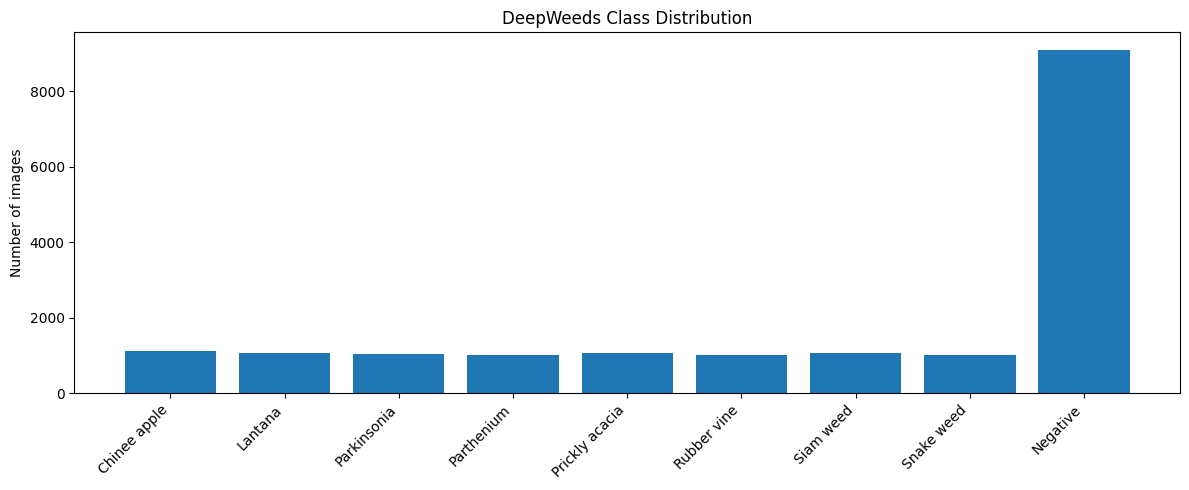

In [10]:

import matplotlib.pyplot as plt

class_counts = (
    df.groupby(["Label", "Species"])
      .size()
      .reset_index(name="Image_Count")
      .sort_values("Label")
)

display(class_counts)

plt.figure(figsize=(12, 5))
plt.bar(class_counts["Species"], class_counts["Image_Count"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("DeepWeeds Class Distribution")
plt.tight_layout()
plt.show()


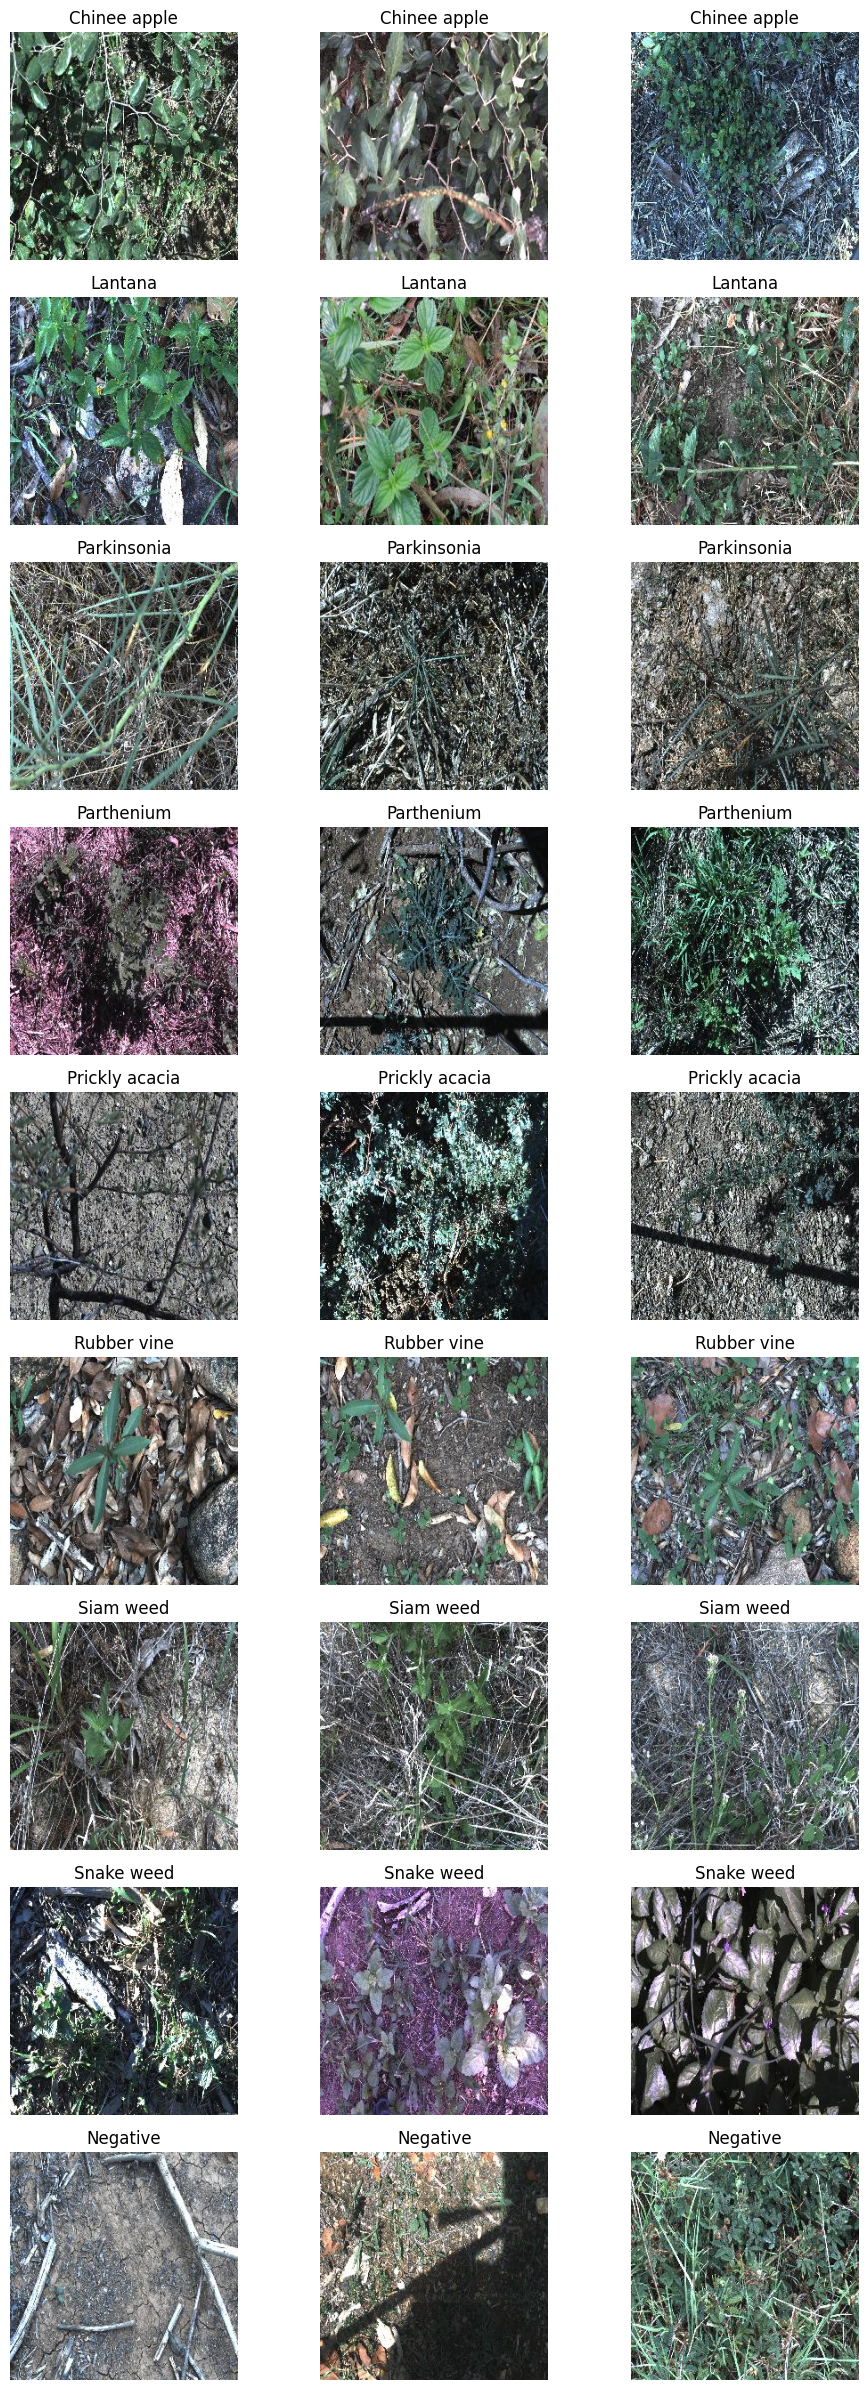

In [11]:

from PIL import Image

fig, axes = plt.subplots(9, 3, figsize=(10, 24))

for label in sorted(df["Label"].unique()):
    samples = df[df["Label"] == label].sample(
        n=3, random_state=42
    )

    for j, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")
        axes[label, j].imshow(img)
        axes[label, j].set_title(row["Species"])
        axes[label, j].axis("off")

plt.tight_layout()
plt.show()


In [12]:

import tensorflow as tf
import numpy as np
import os

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 10

tf.random.set_seed(SEED)
np.random.seed(SEED)

# Use the same class mapping for every split.
class_names = (
    df[["Label", "Species"]]
    .drop_duplicates()
    .sort_values("Label")["Species"]
    .tolist()
)

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)


Classes: ['Chinee apple', 'Lantana', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed', 'Negative']
Number of classes: 9


In [16]:

def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["Label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(dataframe), seed=SEED,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_jpeg(image_bytes, channels=3)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Image pipelines created successfully.")


Image pipelines created successfully.


In [14]:

from sklearn.model_selection import train_test_split

# Recreate the CSV dataframe if needed.
import pandas as pd
import os

CSV_PATH = "/content/DeepWeeds/DeepWeeds-master/labels/labels.csv"
IMAGE_DIR = "/content/DeepWeeds/DeepWeeds-master/images"

df = pd.read_csv(CSV_PATH)
df["image_path"] = df["Filename"].apply(
    lambda name: os.path.join(IMAGE_DIR, name)
)

# Check all images exist.
assert df["image_path"].apply(os.path.isfile).all(), \
    "Some image files are missing!"

# 70% training, 15% validation, 15% testing.
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["Label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))


Training images: 12256
Validation images: 2626
Test images: 2627


In [17]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_names = (
    df[["Label", "Species"]]
    .drop_duplicates()
    .sort_values("Label")["Species"]
    .tolist()
)

num_classes = len(class_names)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=train_df["Label"].to_numpy()
)

class_weights = {
    i: float(w) for i, w in enumerate(weights)
}

print("Number of classes:", num_classes)

for i, name in enumerate(class_names):
    print(f"{name}: weight = {class_weights[i]:.3f}")


Number of classes: 9
Chinee apple: weight = 1.728
Lantana: weight = 1.828
Parkinsonia: weight = 1.886
Parthenium: weight = 1.905
Prickly acacia: weight = 1.833
Rubber vine: weight = 1.929
Siam weed: weight = 1.811
Snake weed: weight = 1.915
Negative: weight = 0.214


In [18]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 10

tf.random.set_seed(42)
np.random.seed(42)

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10)
], name="augmentation")

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:

import os

os.makedirs("outputs", exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "outputs/best_deepweeds.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

model.save("outputs/final_deepweeds.keras")


Epoch 1/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 29s 51ms/step - accuracy: 0.4352 - loss: 1.3693 - val_accuracy: 0.5430 - val_loss: 1.2630 - learning_rate: 0.0010
Epoch 2/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - accuracy: 0.5454 - loss: 1.0100 - val_accuracy: 0.5773 - val_loss: 1.2239 - learning_rate: 0.0010
Epoch 3/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.5655 - loss: 0.9503 - val_accuracy: 0.5274 - val_loss: 1.4311 - learning_rate: 0.0010
Epoch 4/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.5867 - loss: 0.8875 - val_accuracy: 0.5906 - val_loss: 1.1831 - learning_rate: 0.0010
Epoch 5/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.5951 - loss: 0.8752 - val_accuracy: 0.5861 - val_loss: 1.2330 - learning_rate: 0.0010
Epoch 6/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.5910 - loss: 0.8482 - val_accuracy: 0.6112 - val_loss: 1.1537 - learning_rate: 0.0010
Epoch 7/10
383/383 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.6084 - l

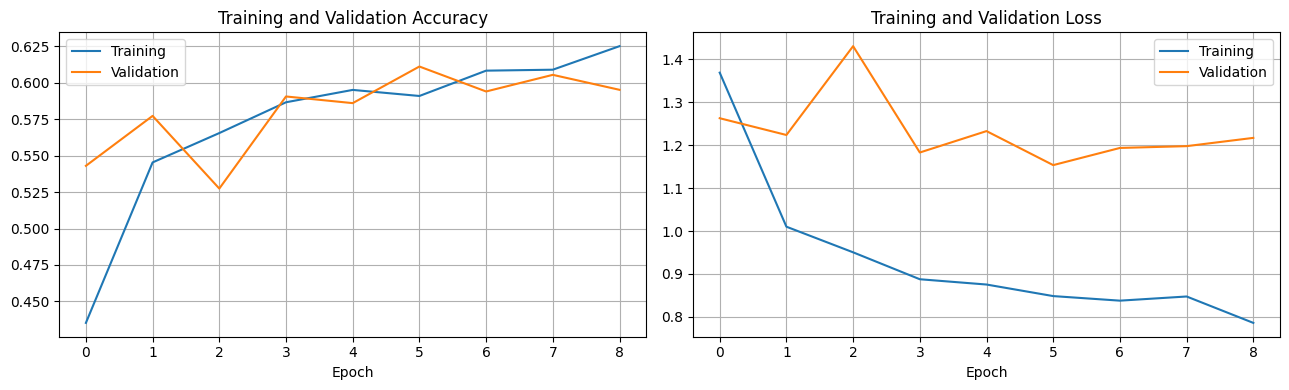

In [20]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("outputs/training_curves.png", dpi=200)
plt.show()


In [21]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

# Load the best model checkpoint.
model = tf.keras.models.load_model(
    "outputs/best_deepweeds.keras"
)

# Get actual test labels.
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Predict the classes.
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Calculate overall metrics.
test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

# Detailed report for all nine classes.
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))

report_df.to_csv("outputs/classification_report.csv")


83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step
Test Accuracy: 0.6098
Macro F1-score: 0.5833


,precision,recall,f1-score,support
Chinee apple,0.4526,0.6213,0.5237,169.0000
Lantana,0.4958,0.7312,0.5909,160.0000
Parkinsonia,0.6734,0.8645,0.7571,155.0000
Parthenium,0.8776,0.2810,0.4257,153.0000
Prickly acacia,0.6855,0.6812,0.6834,160.0000
Rubber vine,0.3318,0.9470,0.4914,151.0000
Siam weed,0.4053,0.8509,0.5491,161.0000
Snake weed,0.5000,0.6447,0.5632,152.0000
Negative,0.9098,0.5242,0.6651,1366.0000
accuracy,0.6098,0.6098,0.6098,0.6098


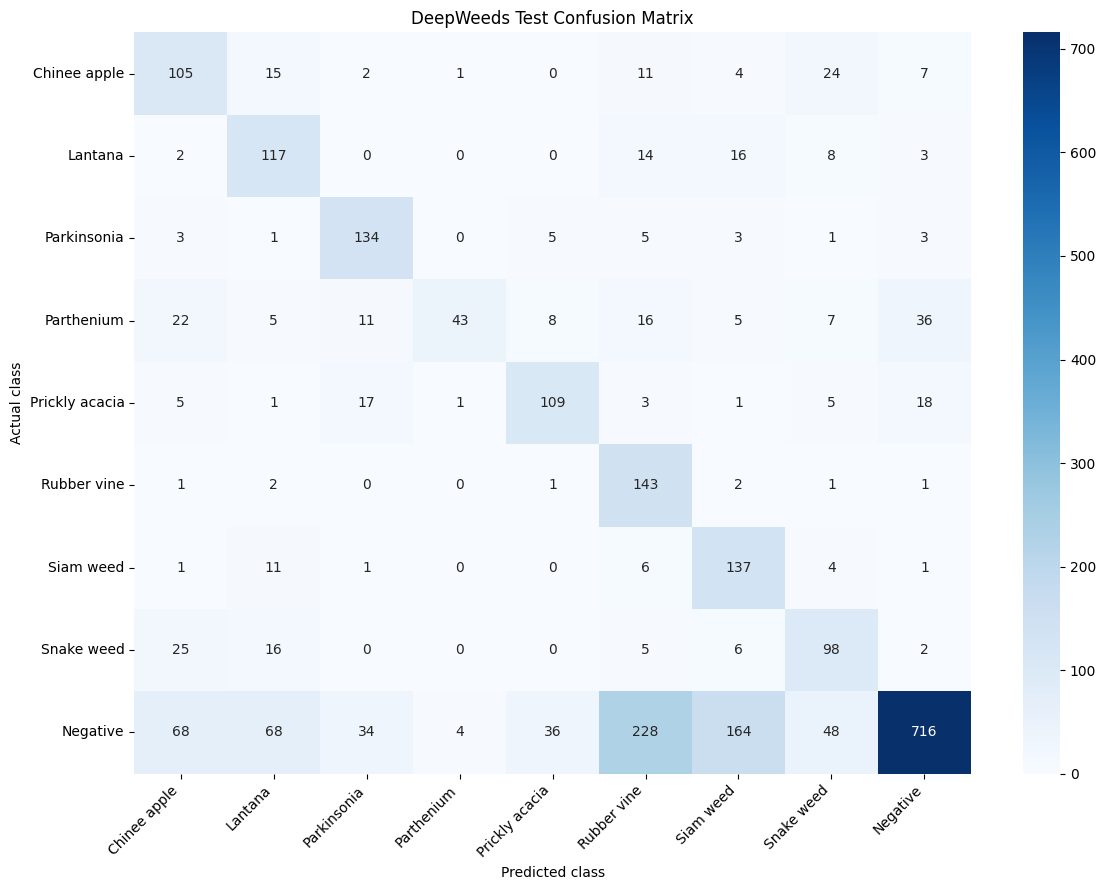

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("DeepWeeds Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("outputs/confusion_matrix.png", dpi=200)
plt.show()


Total incorrect predictions: 1025


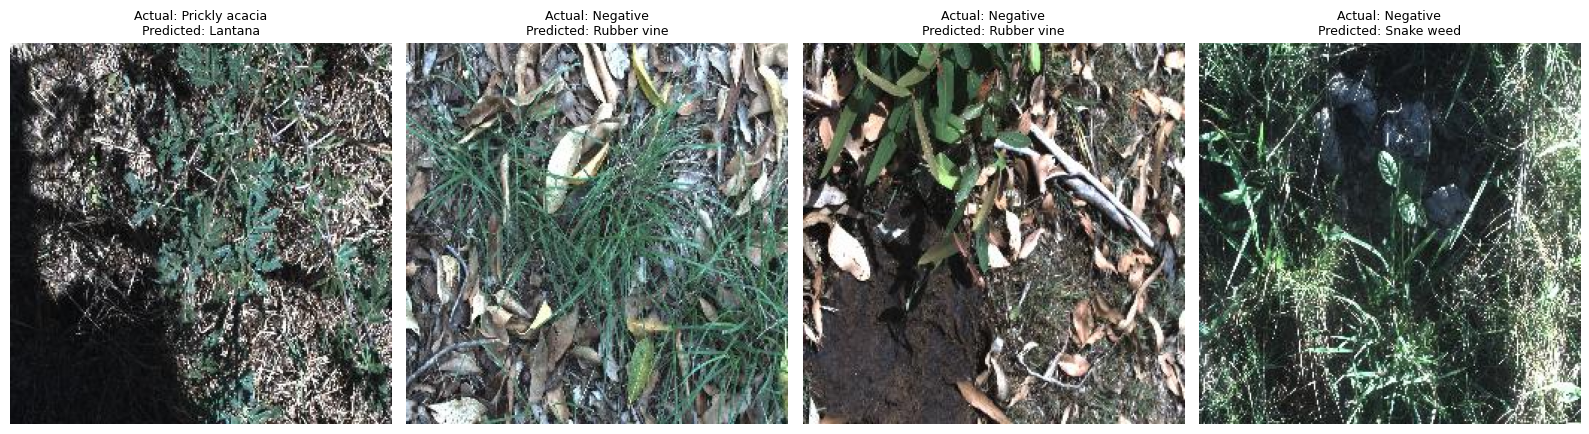

In [23]:

from PIL import Image

wrong_indices = np.flatnonzero(y_true != y_pred)

print("Total incorrect predictions:", len(wrong_indices))

if len(wrong_indices) >= 4:
    selected = wrong_indices[:4]

    # Preserve test_df row order when retrieving images.
    fig, axes = plt.subplots(1, 4, figsize=(16, 5))

    for ax, idx in zip(axes, selected):
        row = test_df.iloc[idx]
        img = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(img)
        ax.set_title(
            f"Actual: {class_names[y_true[idx]]}\n"
            f"Predicted: {class_names[y_pred[idx]]}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.savefig("outputs/misclassified_images.png", dpi=200)
    plt.show()

elif len(wrong_indices) > 0:
    print("Fewer than four errors were found; display all available errors.")
else:
    print("No misclassified images found.")


In [24]:

summary = pd.DataFrame([{
    "Total images": len(df),
    "Training images": len(train_df),
    "Validation images": len(val_df),
    "Test images": len(test_df),
    "Test accuracy": test_accuracy,
    "Macro F1": macro_f1
}])

display(summary)

summary.to_csv("outputs/experiment_summary.csv", index=False)

predictions = pd.DataFrame({
    "actual_class": [class_names[i] for i in y_true],
    "predicted_class": [class_names[i] for i in y_pred],
    "confidence": probabilities.max(axis=1)
})

predictions.to_csv(
    "outputs/test_predictions.csv",
    index=False
)

print("Evaluation files saved in outputs/.")


,Total images,Training images,Validation images,Test images,Test accuracy,Macro F1
0,17509,12256,2626,2627,0.609821,0.583293


Evaluation files saved in outputs/.


In [25]:

import os
import shutil

print("Files generated:")
for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

shutil.make_archive(
    "/content/DeepWeeds_Project_Results",
    "zip",
    "outputs"
)

print("Created /content/DeepWeeds_Project_Results.zip")


Files generated:
outputs/best_deepweeds.keras
outputs/confusion_matrix.png
outputs/training_curves.png
outputs/classification_report.csv
outputs/experiment_summary.csv
outputs/final_deepweeds.keras
outputs/misclassified_images.png
outputs/test_predictions.csv
Created /content/DeepWeeds_Project_Results.zip
